<a href="https://colab.research.google.com/github/2303A51529/QC-Project/blob/main/Quantum_Nearest_Mean_Classifier_S63.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

QUANTUM NEAREST MEAN CLASSIFIER
--------------------------------
Dataset: Wine
Samples: 178
Features: 13
Classes: 3
Class Names: ['class_0' 'class_1' 'class_2']

Density Matrix Shape: (133, 13, 13)

Quantum Centroids Created Successfully

Classification Completed Successfully

       FINAL PERFORMANCE RESULTS
Accuracy            : 0.8889 (88.89%)
Precision           : 0.9042 (90.42%)
Recall              : 0.9074 (90.74%)
Macro F1-Score      : 0.8937 (89.37%)
ROC AUC             : 0.9950 (99.50%)
Specificity         : 0.9455 (94.55%)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     class_0       0.79      1.00      0.88        15
     class_1       1.00      0.72      0.84        18
     class_2       0.92      1.00      0.96        12

    accuracy                           0.89        45
   macro avg       0.90      0.91      0.89        45
weighted avg       0.91      0.89      0.89        45



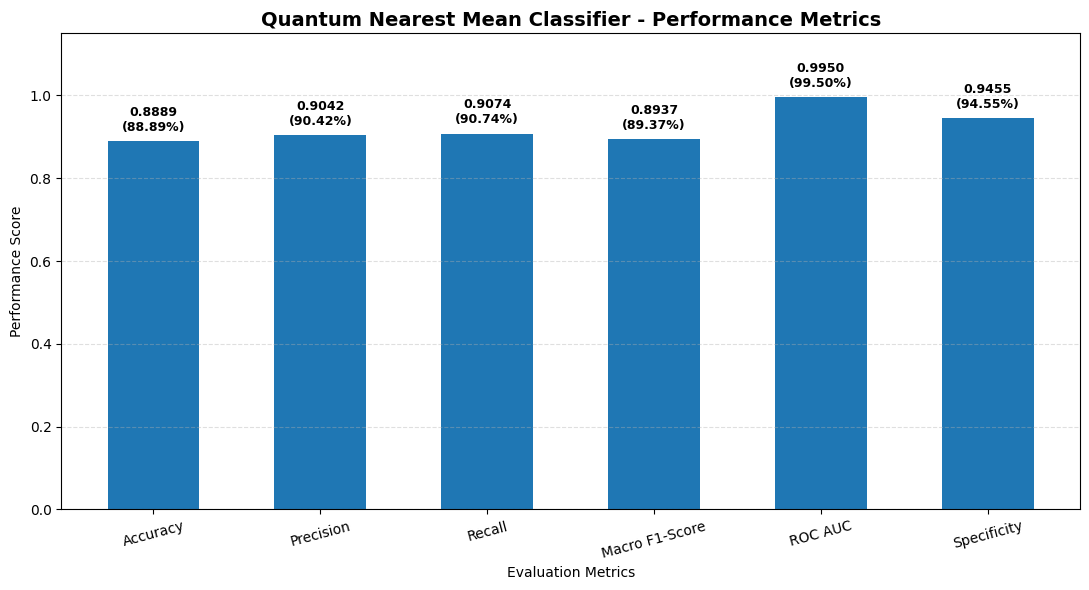

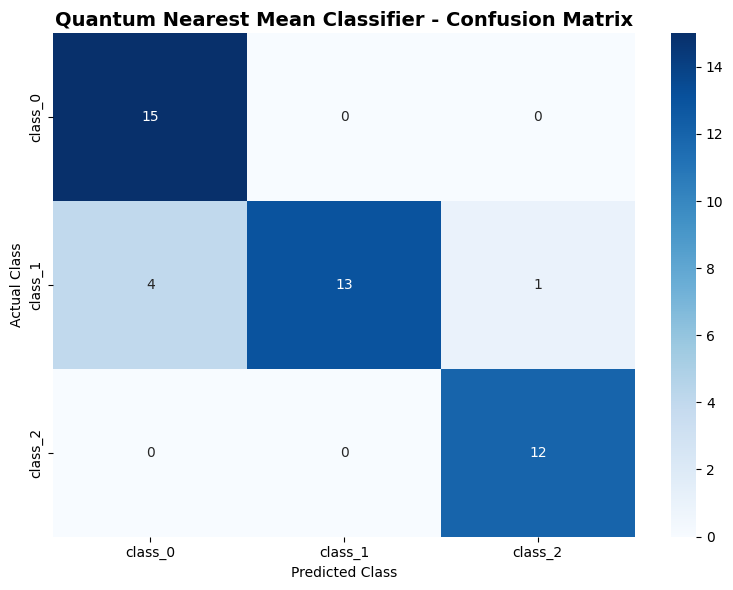

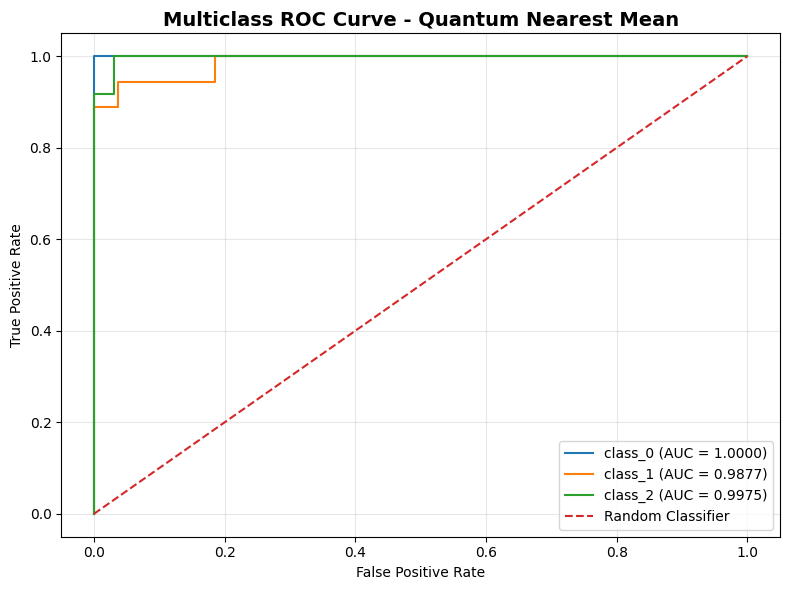


         CLASSICAL MODEL COMPARISON
Quantum Nearest Mean     : 0.8889 (88.89%)
Nearest Centroid         : 0.9333 (93.33%)
KNN                      : 0.9778 (97.78%)
LDA                      : 0.9556 (95.56%)


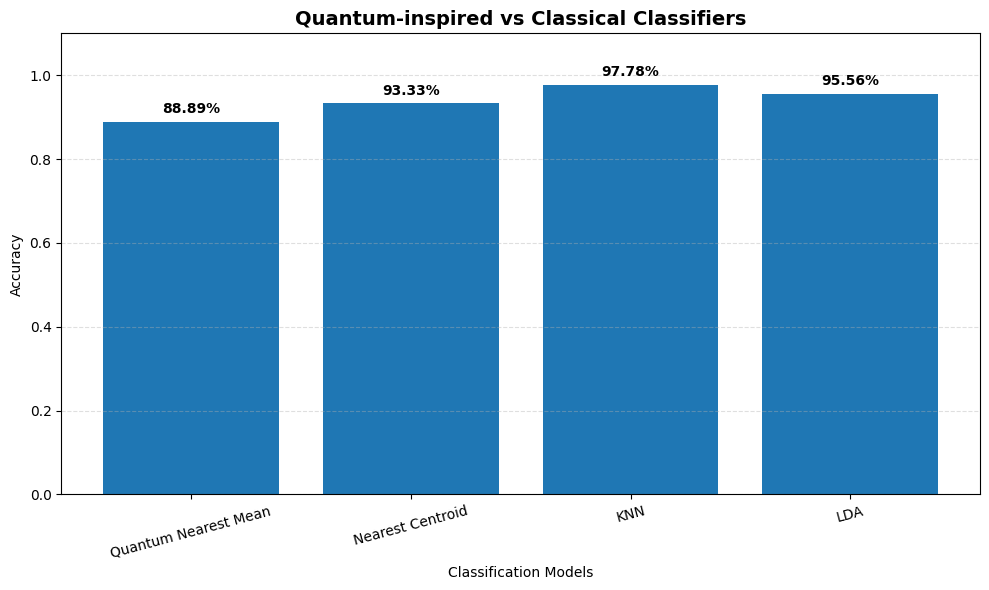


          RESOURCE EVALUATION
Density Matrix Dimension: 13 x 13
Number of Class Centroids: 3
Centroid Storage: 3.9609 KB
Trace Distance Computation Time: 0.009402 seconds
Training Density Matrix Storage: 175.6016 KB
Testing Density Matrix Storage: 59.4141 KB

             PROJECT 63 SUMMARY
Algorithm: Quantum Nearest Mean Classifier
Dataset: Wine
Execution: Classical Density-Matrix Classifier

Final Evaluation:
Accuracy: 88.89%
Precision: 90.42%
Recall: 90.74%
Macro F1-Score: 89.37%
ROC AUC: 99.50%
Specificity: 94.55%

Project Execution Completed Successfully!


In [2]:

# ============================================================
# PROJECT 63: QUANTUM NEAREST MEAN CLASSIFIER
# Dataset: Wine Dataset
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import sys

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, label_binarize
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis


# ============================================================
# 1. LOAD DATASET
# ============================================================

wine = load_wine()

X = wine.data
y = wine.target
class_names = wine.target_names
classes = np.unique(y)

print("QUANTUM NEAREST MEAN CLASSIFIER")
print("--------------------------------")
print("Dataset: Wine")
print("Samples:", X.shape[0])
print("Features:", X.shape[1])
print("Classes:", len(classes))
print("Class Names:", class_names)


# ============================================================
# 2. TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


# ============================================================
# 3. DATA PREPROCESSING
# ============================================================

scaler = MinMaxScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# ============================================================
# 4. DENSITY MATRIX REPRESENTATION
# ============================================================

def density_matrix(x):

    x = np.asarray(x, dtype=float)

    norm = np.linalg.norm(x)

    if norm < 1e-12:
        state = np.zeros_like(x)
        state[0] = 1.0
    else:
        state = x / norm

    rho = np.outer(state, state)

    return rho


train_density = np.array([
    density_matrix(x) for x in X_train
])

test_density = np.array([
    density_matrix(x) for x in X_test
])

print("\nDensity Matrix Shape:", train_density.shape)


# ============================================================
# 5. CALCULATE CLASS QUANTUM CENTROIDS
# ============================================================

centroids = {}

for c in classes:

    class_matrices = train_density[y_train == c]

    centroids[c] = np.mean(
        class_matrices,
        axis=0
    )

print("\nQuantum Centroids Created Successfully")


# ============================================================
# 6. TRACE DISTANCE CALCULATION
# ============================================================

def trace_distance(rho1, rho2):

    difference = rho1 - rho2

    eigenvalues = np.linalg.eigvalsh(difference)

    distance = 0.5 * np.sum(np.abs(eigenvalues))

    return distance


# ============================================================
# 7. PREDICTION
# ============================================================

predictions = []
scores = []

trace_start = time.perf_counter()

for rho in test_density:

    distances = []

    for c in classes:

        distance = trace_distance(
            rho,
            centroids[c]
        )

        distances.append(distance)

    distances = np.array(distances)

    predictions.append(
        classes[np.argmin(distances)]
    )

    scores.append(-distances)


trace_time = time.perf_counter() - trace_start

predictions = np.array(predictions)
scores = np.array(scores)

print("\nClassification Completed Successfully")


# ============================================================
# 8. NORMALIZED CLASS SCORES
# ============================================================

exp_scores = np.exp(
    scores - np.max(scores, axis=1, keepdims=True)
)

probabilities = exp_scores / np.sum(
    exp_scores,
    axis=1,
    keepdims=True
)


# ============================================================
# 9. PERFORMANCE METRICS
# ============================================================

accuracy = accuracy_score(
    y_test, predictions
)

precision = precision_score(
    y_test,
    predictions,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_test,
    predictions,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_test,
    predictions,
    average="macro",
    zero_division=0
)

y_test_binary = label_binarize(
    y_test,
    classes=classes
)

roc_auc = roc_auc_score(
    y_test_binary,
    probabilities,
    average="macro",
    multi_class="ovr"
)


# ============================================================
# 10. SPECIFICITY CALCULATION
# ============================================================

cm = confusion_matrix(
    y_test,
    predictions,
    labels=classes
)

specificities = []

for i in range(len(classes)):

    tp = cm[i, i]

    fp = cm[:, i].sum() - tp

    fn = cm[i, :].sum() - tp

    tn = cm.sum() - tp - fp - fn

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    specificities.append(specificity)

macro_specificity = np.mean(specificities)


# ============================================================
# 11. PRINT FINAL PERFORMANCE RESULTS
# ============================================================

metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "Macro F1-Score": macro_f1,
    "ROC AUC": roc_auc,
    "Specificity": macro_specificity
}

print("\n==========================================")
print("       FINAL PERFORMANCE RESULTS")
print("==========================================")

for name, value in metrics.items():

    print(
        f"{name:20s}: {value:.4f} ({value * 100:.2f}%)"
    )

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        predictions,
        target_names=class_names,
        zero_division=0
    )
)


# ============================================================
# 12. PERFORMANCE METRICS DIAGRAM
# ============================================================

plt.figure(figsize=(11, 6))

bars = plt.bar(
    metrics.keys(),
    metrics.values(),
    width=0.55
)

plt.title(
    "Quantum Nearest Mean Classifier - Performance Metrics",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Evaluation Metrics")
plt.ylabel("Performance Score")

plt.ylim(0, 1.15)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

for bar, value in zip(bars, metrics.values()):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.025,
        f"{value:.4f}\n({value * 100:.2f}%)",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# ============================================================
# 13. CONFUSION MATRIX
# ============================================================

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "Quantum Nearest Mean Classifier - Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()


# ============================================================
# 14. ROC CURVE
# ============================================================

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(class_names):

    fpr, tpr, thresholds = roc_curve(
        y_test_binary[:, i],
        probabilities[:, i]
    )

    class_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {class_auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title(
    "Multiclass ROC Curve - Quantum Nearest Mean",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 15. CLASSICAL MODEL COMPARISON
# ============================================================

models = {

    "Quantum Nearest Mean": None,

    "Nearest Centroid": NearestCentroid(),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "LDA": LinearDiscriminantAnalysis()

}

comparison = {}

comparison["Quantum Nearest Mean"] = accuracy

for name, model in models.items():

    if model is None:
        continue

    model.fit(
        X_train,
        y_train
    )

    pred = model.predict(X_test)

    comparison[name] = accuracy_score(
        y_test,
        pred
    )


print("\n==========================================")
print("         CLASSICAL MODEL COMPARISON")
print("==========================================")

for name, value in comparison.items():

    print(
        f"{name:25s}: {value:.4f} ({value * 100:.2f}%)"
    )


# ============================================================
# 16. MODEL COMPARISON DIAGRAM
# ============================================================

plt.figure(figsize=(10, 6))

bars = plt.bar(
    comparison.keys(),
    comparison.values()
)

plt.title(
    "Quantum-inspired vs Classical Classifiers",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Classification Models")
plt.ylabel("Accuracy")

plt.ylim(0, 1.1)

plt.xticks(rotation=15)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

for bar, value in zip(bars, comparison.values()):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value * 100:.2f}%",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()


# ============================================================
# 17. RESOURCE EVALUATION
# ============================================================

density_dimension = train_density.shape[1]

centroid_storage = sum(
    matrix.nbytes
    for matrix in centroids.values()
)

print("\n==========================================")
print("          RESOURCE EVALUATION")
print("==========================================")

print(
    "Density Matrix Dimension:",
    density_dimension,
    "x",
    density_dimension
)

print(
    "Number of Class Centroids:",
    len(centroids)
)

print(
    "Centroid Storage:",
    round(centroid_storage / 1024, 4),
    "KB"
)

print(
    "Trace Distance Computation Time:",
    round(trace_time, 6),
    "seconds"
)

print(
    "Training Density Matrix Storage:",
    round(train_density.nbytes / 1024, 4),
    "KB"
)

print(
    "Testing Density Matrix Storage:",
    round(test_density.nbytes / 1024, 4),
    "KB"
)


# ============================================================
# 18. FINAL SUMMARY
# ============================================================

print("\n==========================================")
print("             PROJECT 63 SUMMARY")
print("==========================================")

print("Algorithm: Quantum Nearest Mean Classifier")
print("Dataset: Wine")
print("Execution: Classical Density-Matrix Classifier")

print("\nFinal Evaluation:")

for name, value in metrics.items():

    print(f"{name}: {value * 100:.2f}%")

print("\nProject Execution Completed Successfully!")
